# Example 02: build the ST40 PCS preshot (`st40_tepcs`)

A **preshot** is everything `rtgsfit()` needs that does not change during a pulse: the grid and limiter,
the order of the measurements and coil signals, the Greens functions, the precomputed fit and Poisson
matrices, and the initial plasma. It is compiled into `librtgsfit.so`, so a new preshot means a new build.

This notebook rebuilds the ST40 campaign preshot **RTGSFIT 99000230 / PRESHOT10** from GSFit with the
packaged `st40_tepcs` recipe, checks it against the stored copy that the PCS compiles, and compiles it.

```text
st40_tepcs settings -> GSFit machine description -> build_preshot -> Preshot
Preshot == stored PRESHOT10? -> local NPZ + C preshot file -> make PRESHOT_FILE=... -> librtgsfit.so
optional: Preshot -> new private MDSplus run -> make SHOT=... RUN_NAME=... (C only, as the PCS builds)
```

| Step | What runs |
|---|---|
| 1 | Choose the recipe and a new local output directory |
| 2 | Show the recipe: GSFit settings, grid, sensors and coil circuits |
| 3 | Build the preshot with GSFit (under a minute) |
| 4 | Inspect it: the inputs the PCS supplies, the grid, and the coil and passive Greens functions |
| 5 | Compare it with the stored PRESHOT10 |
| 6 | Save it locally, compile it, and check the compiled checksum |
| 7 | Optionally write it to a new private MDSplus run and compile that run with C only |
| 8 | How to publish a new campaign preshot for the PCS |

**Default: no database writes.** RTGSFIT 99000230 is the shared PCS preshot pulse and is only read.
`WRITE_MDSPLUS = True` writes the preshot to an unused run in your private pulse space; it never
overwrites a run and never changes `BEST`.
See [README.md](README.md) for requirements and [helpers.py](helpers.py) for checks and plots.
[Example 01](../example_01_run_full_pipeline_pcs_mock/README.md) runs the C solver on a pulse with this preshot.
Restart the kernel before running all cells; do not run another build against the same C directory.

In [1]:
import subprocess
import time
from datetime import UTC
from datetime import datetime

import helpers
from rtgsfit import load_settings
from rtgsfit.database_readers.local import read_preshot as read_local_preshot
from rtgsfit.database_writers.c_source import preshot_checksum
from rtgsfit.database_writers.c_source import write_preshot_file
from rtgsfit.database_writers.local import write_npz
from rtgsfit.database_writers.rtgsfit_mdsplus import RtgsfitMdsplusWriter
from rtgsfit.library import Rtgsfit
from rtgsfit.library import c_directory
from rtgsfit.library import cache_directory
from rtgsfit.replay import build_preshot
from rtgsfit.replay import preshot_location
from rtgsfit.replay import read_preshot

## 1. Recipe and outputs

`st40_tepcs` is the recipe for the PCS preshot: GSFit's ST40 machine description with the sensors and
coil channels that the PCS reads (TEPCS). PRESHOT10 was built from it, so this build should reproduce
PRESHOT10. The settings are used unchanged: the preshot archives them (`INFO:SETTINGS`), and the
comparison in step 5 checks them.

Every run gets a new local output directory. To also write to MDSplus, set `WRITE_MDSPLUS = True` with
your own allocated private pulse and an unused run name (a Python identifier of at most 12 characters).

In [2]:
SETTINGS_NAME = "st40_tepcs"
WRITE_MDSPLUS = False
PRIVATE_PULSE = 52_014_922
PRIVATE_RUN = "EXAMPLE02"
PRIVATE_DESCRIPTION = "Example 02: st40_tepcs preshot rebuilt by GSFit"

settings = load_settings(SETTINGS_NAME)
stored_pulse = int(settings["preshot"]["rtgsfit_mdsplus"]["pulse"])
stored_run = str(settings["preshot"]["rtgsfit_mdsplus"]["run_name"])
if WRITE_MDSPLUS:
    if PRIVATE_PULSE == stored_pulse:
        raise ValueError(f"{stored_pulse} holds the shared PCS preshots; choose your own private pulse")
    if not PRIVATE_RUN.isidentifier() or len(PRIVATE_RUN) > 12 or PRIVATE_RUN.upper() == "BEST":
        raise ValueError(f"invalid PRIVATE_RUN {PRIVATE_RUN!r}: use an identifier of at most 12 characters, not BEST")

helpers.check_environment(write_mdsplus=WRITE_MDSPLUS)
if WRITE_MDSPLUS:
    helpers.require_free_run(PRIVATE_PULSE, PRIVATE_RUN)

stamp = datetime.now(UTC).strftime("%Y%m%dT%H%M%S%fZ")
output_dir = cache_directory().resolve() / "example_02_build_preshot" / stamp
output_dir.mkdir(parents=True, exist_ok=False)
print(f"Stored preshot (read only): RTGSFIT {stored_pulse} {stored_run}")
print(f"Local outputs: {output_dir}")
print(f"MDSplus preshot write: {f'RTGSFIT {PRIVATE_PULSE} {PRIVATE_RUN}' if WRITE_MDSPLUS else 'disabled'}")

rtgsfit 0.2.0 from ./python/rtgsfit
gsfit 0.0.12 from ./.venv/lib/python3.13/site-packages/gsfit
gsfit_rs  from ./.venv/lib/python3.13/site-packages/gsfit_rs
shapely 2.2.0 from ./.venv/lib/python3.13/site-packages/shapely
mdsthin  from ./.venv/lib/python3.13/site-packages/mdsthin
MDSplus server smaug is reachable
Stored preshot (read only): RTGSFIT 99000230 PRESHOT10
Local outputs: ./c/cache/example_02_build_preshot/20261125T112921409928Z
MDSplus preshot write: disabled


## 2. The recipe

The GSFit builder (`preshot/builder = gsfit`) sets up GSFit with the `gsfit/settings_path` settings for
`replay/pulse`, and takes the machine description from it: PF coils, passive structures, sensors and
limiter. The rest of the `gsfit` section chooses what RT-GSFit uses: the grid, the PCS sensor list
(`sensor_names`), the Rogowski coils, the coil circuits and the PCS channels that drive them, and the
replacements for Rogowski coils that the PCS does not read.
[Manual: the preshot](../../documentation/manual.md#5-the-preshot).

In [3]:
gsfit = settings["gsfit"]
grid = gsfit["grid"]
circuits = gsfit["coils"]["groups"]
print(f"builder: {settings['preshot']['builder']}, with GSFit settings {gsfit['settings_path']}")
print(f"machine description: ST40 pulse {settings['replay']['pulse']}")
print(f"grid: {grid['n_r']} x {grid['n_z']} points")
print(f"  R from {grid['r_min']} to {grid['r_max']} m, Z from {grid['z_min']} to {grid['z_max']} m")
print(f"sensors: {gsfit['sensor_names']}; Rogowski coils: {', '.join(gsfit['rogowski_names'])}")
print("coil circuits: " + "; ".join(f"{name} = {' + '.join(coils)}" for name, coils in circuits.items()))
print(f"PCS coil channels: {', '.join(gsfit['coils']['signals'])}")
print(f"Rogowski coils replaced by flux loop voltages: {', '.join(gsfit['sensor_replacements'])}")
print(f"Stored copy: {preshot_location(settings)}")

builder: gsfit, with GSFit settings st40_setup_for_rtgsfit
machine description: ST40 pulse 14922
grid: 33 x 65 points
  R from 0.11 to 1.07 m, Z from -0.96 to 0.96 m
sensors: st40_pcs; Rogowski coils: INIVC000, BVLT, BVLB, GASBFLT, GASBFLB, HFSPSRT, HFSPSRB, DIVPSRT, DIVPSRB
coil circuits: SOL = SOL; MCT = MCT; MCB = MCB; DIV = DIVT + DIVB; BVL = BVLT + BVLB; BVUT = BVUT; BVUB = BVUB; PSH = PSHT + PSHB
PCS coil channels: I_BVL_PSU, I_BVUB_PSU, I_BVUT_PSU, I_DIV_PSU, I_MCVC_PSU, I_PSH_PSU, I_ROG_MCWIRE, I_SOL_PSU
Rogowski coils replaced by flux loop voltages: I_ROG_DIVPSRB, I_ROG_DIVPSRT, I_ROG_GASBFLB, I_ROG_GASBFLT, I_ROG_HFSPSRB, I_ROG_HFSPSRT
Stored copy: rtgsfit_mdsplus {"pulse": 99000230, "run_name": "PRESHOT10", "legacy_schema": false}


## 3. Build the preshot

`build_preshot` sets up GSFit and computes everything `rtgsfit()` needs from it. It takes under a
minute, mostly in GSFit, which logs each step. `rtgsfit preshot st40_tepcs` does the same from the command line, then runs the
writers.

The checksum is the CRC-32 of the values compiled into C. The library reports it, so a library can be
checked against a preshot.

In [4]:
start = time.perf_counter()
preshot = build_preshot(settings)
print(f"Built in {time.perf_counter() - start:.0f} s from {preshot['INFO:SOURCE']}")
print(preshot.summary())
print(f"C checksum: {preshot_checksum(preshot):08X}")

2026-11-25 11:29:21  |  GSFIT  |  diagnostic_and_simulation_base.py:216  |  INFO  |  Loading settings from: "GSFIT_code_settings.json"
2026-11-25 11:29:21  |  GSFIT  |  diagnostic_and_simulation_base.py:216  |  INFO  |  Loading settings from: "RTGSFIT_code_settings.json"
2026-11-25 11:29:21  |  GSFIT  |  diagnostic_and_simulation_base.py:216  |  INFO  |  Loading settings from: "passive_dof_regularisation.json"
2026-11-25 11:29:21  |  GSFIT  |  diagnostic_and_simulation_base.py:216  |  INFO  |  Loading settings from: "rtgsfit_initial_conditions.json"
2026-11-25 11:29:21  |  GSFIT  |  diagnostic_and_simulation_base.py:216  |  INFO  |  Loading settings from: "sensor_replacement.json"
2026-11-25 11:29:21  |  GSFIT  |  diagnostic_and_simulation_base.py:216  |  INFO  |  Loading settings from: "sensor_weights_bp_probe.json"
2026-11-25 11:29:21  |  GSFIT  |  diagnostic_and_simulation_base.py:216  |  INFO  |  Loading settings from: "sensor_weights_dialoop.json"
2026-11-25 11:29:21  |  GSFIT  | 

## 4. Inspect the preshot

The preshot fixes the order of the two inputs that the caller of `rtgsfit()` supplies every cycle:
`mag_signal`, in `CONSTRAINT:MAG_SIGNALS` order, and the coil currents, in `COIL:NAMES` order. The PCS computes the coil
currents from its channels, in `COIL:COIL_SIGNALS` order, with `COIL:MATRIX`. A row of zeros fixes a coil's
current at zero: here PSH, so `I_PSH_PSU` is not used.

In [5]:
helpers.print_pcs_inputs(preshot)

mag_signal: 56 values in CONSTRAINT:MAG_SIGNALS order: 26 flux loops, 21 Bp probes, 3 Rogowski coils, 6 flux loop voltages
  first PSI_FLOOP_001, PSI_FLOOP_002, PSI_FLOOP_004; last V_FLOOP_007, V_FLOOP_009, V_FLOOP_011
coil signals: 8 PCS channels in COIL:COIL_SIGNALS order: I_BVL_PSU, I_BVUB_PSU, I_BVUT_PSU, I_DIV_PSU, I_MCVC_PSU, I_PSH_PSU, I_ROG_MCWIRE, I_SOL_PSU
coil_current = coil_signal @ COIL:MATRIX, one value per COIL:NAMES:
  SOL   I = I_SOL_PSU
  MCT   I = I_ROG_MCWIRE
  MCB   I = I_MCVC_PSU + I_ROG_MCWIRE
  DIV   I = I_DIV_PSU
  BVL   I = I_BVL_PSU
  BVUT  I = I_BVUT_PSU
  BVUB  I = I_BVUB_PSU
  PSH   I = 0: no signal


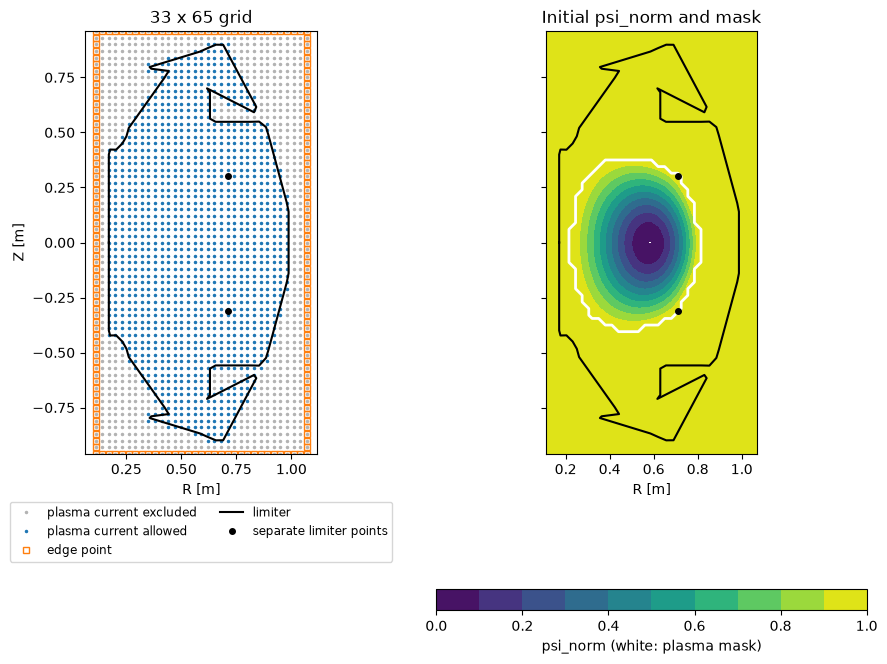

In [6]:
figure = helpers.plot_preshot(preshot)

The Greens functions come from the GSFit machine description. `gsfit_geometry` collects the coils and
passive structures from the GSFit controller that `build_preshot` set up (it is cached, so GSFit is not
set up again), to draw them with the flux they make. Each panel is one PF coil circuit; its coils are red.

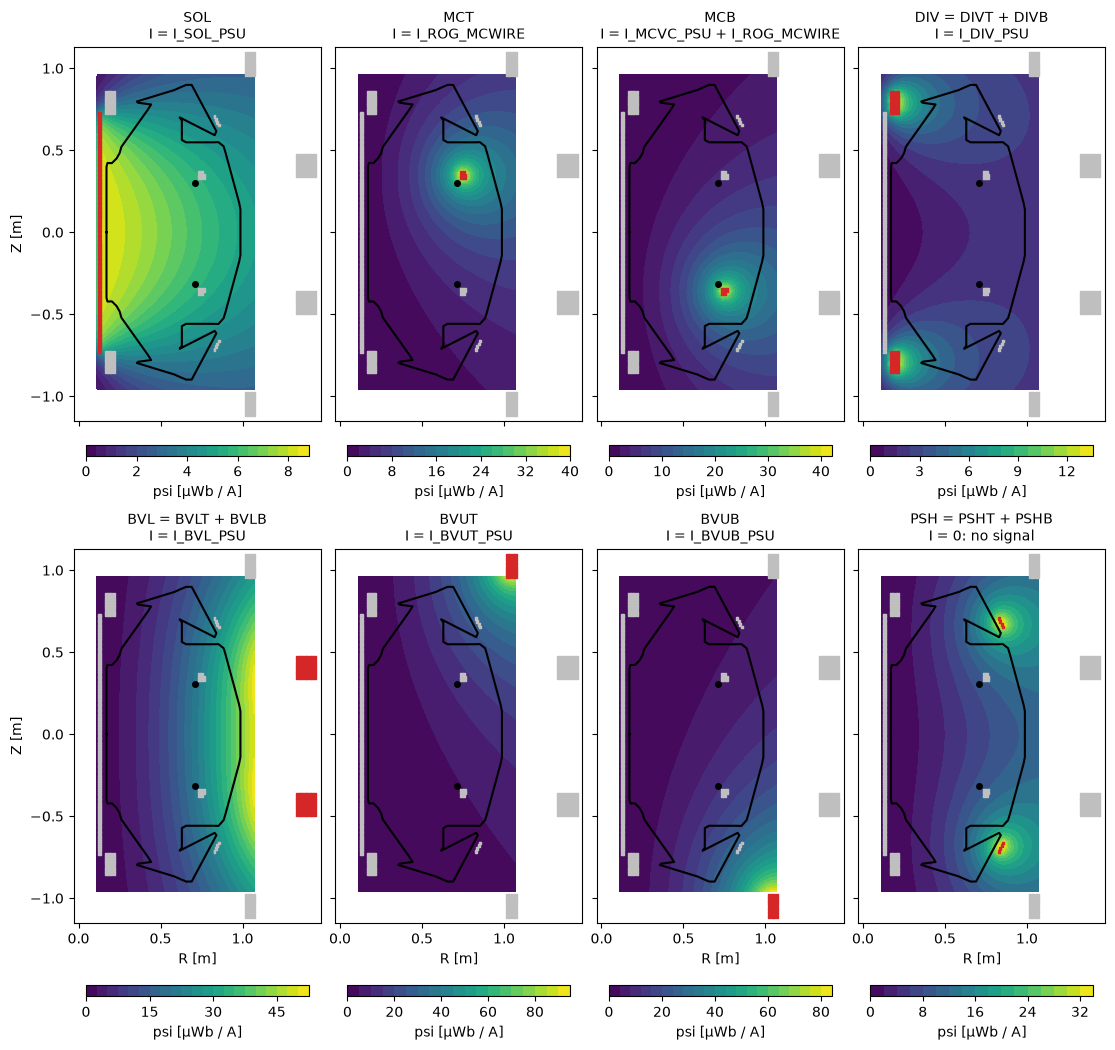

In [7]:
geometry = helpers.gsfit_geometry(settings)
figure = helpers.plot_coil_greens(preshot, geometry)

The passive structures are fitted as degrees of freedom (DOFs): a constant current density in each
structure, or, for the in-vessel components (IVC), the slowest eigenmodes of their L/R circuit equation.
The bars show each eigenmode's time constant, net current and regularisation weight; the maps below
show the flux of the first eigenmodes and of every other passive DOF.

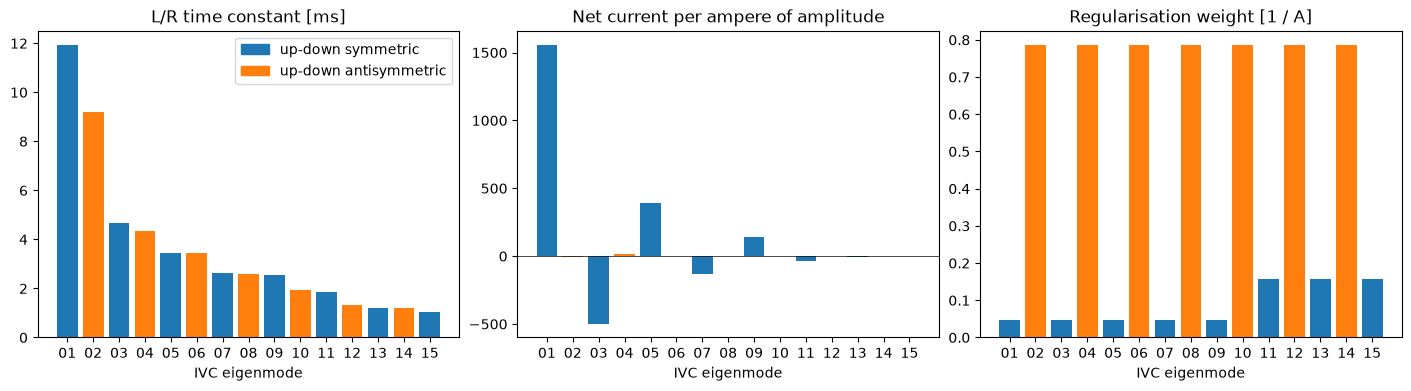

In [8]:
figure = helpers.plot_eigenmodes(preshot, geometry)

22 passive DOFs: 15 IVC eigenmodes and 7 other structures


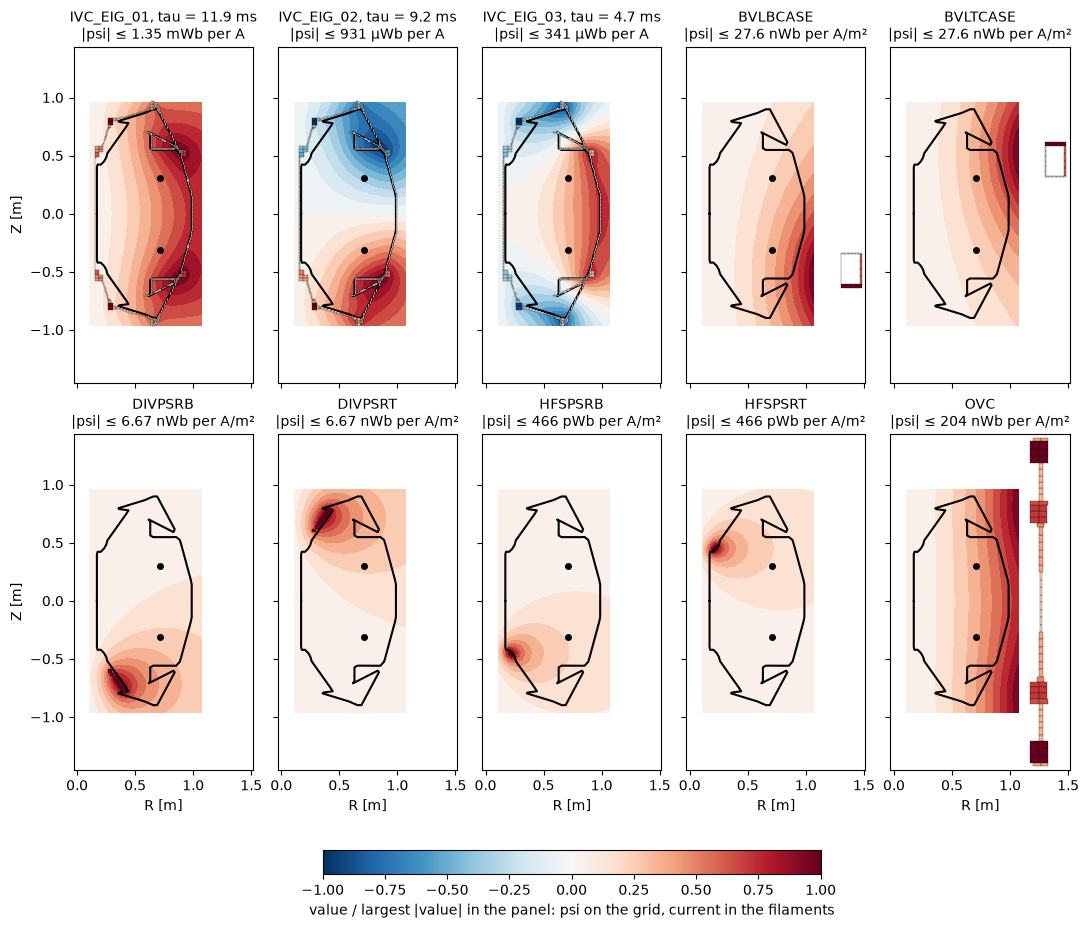

In [9]:
passive_dofs = list(preshot["FIT:DOF_NAMES"][int(preshot["SIZES:N_PLASMA"]) :])
eigenmodes = [name for name in passive_dofs if name in geometry.time_constant]
shown = eigenmodes[:3] + [name for name in passive_dofs if name not in geometry.time_constant]
n_structures = len(passive_dofs) - len(eigenmodes)
print(f"{len(passive_dofs)} passive DOFs: {len(eigenmodes)} IVC eigenmodes and {n_structures} other structures")
figure = helpers.plot_passive_greens(preshot, geometry, shown)

## 5. Compare with the stored PRESHOT10

PRESHOT10 was built with the same recipe and stored in MDSplus, where the PCS reads it. Every node is
compared: floating-point values to 1e-12 of their largest value, everything else exactly.
`INFO:SETTINGS` must agree in its `preshot` and `gsfit` sections, which determine the preshot.

The Poisson LU factors come from a threaded LAPACK factorisation, whose rounding can depend on the
machine and the number of threads. PRESHOT10 was built with the default number of OpenBLAS threads, so
this notebook does not set `OPENBLAS_NUM_THREADS`. With `OPENBLAS_NUM_THREADS=1`, the LU factors differ
from PRESHOT10 by about 3e-16 of their size: the solution is the same, but the C checksum is not. Only a
bit-for-bit identical build compiles to the same library as PRESHOT10.

In [10]:
stored = read_preshot(settings)
identical = helpers.compare_preshots(preshot, stored)
print(f"C checksum: built {preshot_checksum(preshot):08X}, stored {preshot_checksum(stored):08X}")
if identical:
    print(f"The build reproduces {stored_run} bit for bit, so it compiles to the same library")
else:
    print(f"The build matches {stored_run} to round-off; its C checksum differs, so it compiles to another library")

61 of 61 nodes are bit-for-bit identical
C checksum: built 431C9A97, stored 431C9A97
The build reproduces PRESHOT10 bit for bit, so it compiles to the same library


## 6. Save, compile and check

The local NPZ holds every node, and reads back exactly. The C preshot file holds only the values
compiled into C: `make PRESHOT_FILE=...` turns it into `c/src/preshot_sizes.h` and `c/src/preshot_data.c`
and compiles `librtgsfit.so`. `Rtgsfit` then checks that the library's sizes and checksum match the
preshot in memory. [Manual: building](../../documentation/manual.md#66-building).

In [11]:
npz_path = write_npz(output_dir / "st40_tepcs_preshot.npz", preshot.to_nested())
helpers.assert_identical(read_local_preshot(npz_path), preshot)
preshot_file = write_preshot_file(preshot, output_dir / "st40_tepcs_preshot.bin")
print(f"Wrote {npz_path.name} and {preshot_file.name} to {output_dir}")

All 61 nodes are identical
Wrote st40_tepcs_preshot.npz and st40_tepcs_preshot.bin to ./c/cache/example_02_build_preshot/20261125T112921409928Z


In [12]:
c_root = c_directory().resolve()
build = settings["build"]
build_flags = [f"TIMING={int(build['timing'])}", f"ARCH_FLAGS={build['arch_flags']}"]
subprocess.run(["make", "-C", str(c_root), f"PRESHOT_FILE={preshot_file}", *build_flags], check=True)
library_path = c_root / "build" / "librtgsfit.so"
solver = Rtgsfit(library_path, preshot, timing=build["timing"])
print(f"Loaded {library_path}: sizes and checksum {preshot_checksum(preshot):08X} match the preshot")

make: Entering directory './c'
./c/build/write_preshot --file ./c/cache/example_02_build_preshot/20261125T112921409928Z/st40_tepcs_preshot.bin ./c/src
./c/src/preshot_sizes.h is unchanged
./c/src/preshot_data.c is unchanged
make: Leaving directory './c'
Loaded ./c/build/librtgsfit.so: sizes and checksum 431C9A97 match the preshot


## 7. Optional: write to a private MDSplus run and build it with C only

Disabled by default. With `WRITE_MDSPLUS = True`, this writes the preshot to `PRIVATE_RUN` at
`PRIVATE_PULSE`, reads it back and checks that every node is identical, then builds `librtgsfit.so`
from that run as the PCS does: `make SHOT=... RUN_NAME=...` reads MDSplus with
`c/tools/write_preshot.c`, without Python. Only a copy of the settings, used to write, names the private
run, so `INFO:SETTINGS` still records the packaged recipe. Writing needs `standard_utility`, its
matching `RTGSFIT.csv` and database write access.

In [13]:
if WRITE_MDSPLUS:
    helpers.require_free_run(PRIVATE_PULSE, PRIVATE_RUN)
    writer_settings = settings.copy_with(
        {
            "writers/rtgsfit_mdsplus/enabled": True,
            "writers/rtgsfit_mdsplus/pulse": PRIVATE_PULSE,
            "writers/rtgsfit_mdsplus/run_name": PRIVATE_RUN,
            "writers/rtgsfit_mdsplus/run_description": PRIVATE_DESCRIPTION,
            "writers/rtgsfit_mdsplus/link_best": False,
        }
    )
    RtgsfitMdsplusWriter().write_preshot(preshot, writer_settings)
    private_settings = settings.copy_with(
        {"preshot/rtgsfit_mdsplus/pulse": PRIVATE_PULSE, "preshot/rtgsfit_mdsplus/run_name": PRIVATE_RUN}
    )
    helpers.assert_identical(read_preshot(private_settings), preshot)
    subprocess.run(
        ["make", "-C", str(c_root), f"SHOT={PRIVATE_PULSE}", f"RUN_NAME={PRIVATE_RUN}", *build_flags], check=True
    )
    solver = Rtgsfit(library_path, preshot, timing=build["timing"])
    print(f"Built {library_path} from RTGSFIT {PRIVATE_PULSE} {PRIVATE_RUN} with C only; checksum matches")
else:
    print("MDSplus write skipped: WRITE_MDSPLUS = False. The PCS builds the stored preshot with C only:")
    print(f"  make -C c SHOT={stored_pulse} RUN_NAME={stored_run}")

MDSplus write skipped: WRITE_MDSPLUS = False. The PCS builds the stored preshot with C only:
  make -C c SHOT=99000230 RUN_NAME=PRESHOT10


## 8. Publishing a new campaign preshot for the PCS

Publishing changes what the PCS compiles. It is a deployment step to agree with the PCS team, and this
notebook does not do it. To publish, e.g. after a change to the machine description or the recipe:

1. Change the recipe, and set `preshot/rtgsfit_mdsplus/run_name` to a new run (e.g. `PRESHOT09`)
   **before** building, so that `INFO:SETTINGS` records where the preshot is published.
2. Build and check it as above, and replay pulses with it ([Example 01](../example_01_run_full_pipeline_pcs_mock/README.md)).
3. Write it to the new run at 99000230 and read it back. Never overwrite a run, and do not link `BEST`.
4. Build it as the PCS will: `make -C c SHOT=99000230 RUN_NAME=PRESHOT09`.
5. The PCS team then selects the new run (`runName` in the PCS repository's `config-ci.yml`).

ST40 pulses before 12551 have no MCVC coil channel and use PRESHOT11, built in the same way without
`I_MCVC_PSU` ([Manual: the preshot](../../documentation/manual.md#5-the-preshot)).

From the repository root, the command-line equivalents are:

```sh
rtgsfit preshot st40_tepcs
make -C c SHOT=99000230 RUN_NAME=PRESHOT10 TIMING=1
```

The first builds the preshot and writes it with the default local writer, to
`c/cache/rtgsfit_st40_tepcs_preshot.npz` in a checkout. The second is the PCS build of the stored
PRESHOT10, which needs no Python.